In [4]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
from sklearn.model_selection import train_test_split
import numpy as np
from xgboost import XGBClassifier
from tree.mini_xgboost_classifier import MiniXGBoostClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from tree.vectorized_single_hist_tree_boost import VectorizedSingleHistTreeBoost
from sklearn.datasets import make_classification
import shap
import matplotlib.pyplot as plt
import pandas as pd
from typing import Tuple
import polars as pl

In [5]:
df = pd.read_parquet("../datasets/BRFSS/out.parquet")

In [7]:
df["INCOME"] = df["INCOME"].astype(dtype="Int8")
df["SEX"] = df["SEX"].astype(dtype="Int8")
df["HIGHBP"] = df["HIGHBP"].astype(dtype="Int8")
df["HIGHCHOL"] = df["HIGHCHOL"].astype(dtype="Int8")
df["DRINK"] = df["DRINK"].astype(dtype="Int8")
df["INSURANCE"] = df["INSURANCE"].astype(dtype="Int8")
df["AGE"] = df["AGE"].astype(dtype="Int8")
df["RACE"] = df["RACE"].astype(dtype="Int8")
df["MARITAL"] = df["MARITAL"].astype(dtype="Int8")
df["EDUCATION"] = df["EDUCATION"].astype(dtype="Int8")
df["EMPLOYMENT"] = df["EMPLOYMENT"].astype(dtype="Int8")
df["BMI"] = df["BMI"].astype(dtype="Int8")
df["HEALTH"] = df["HEALTH"].astype(dtype="Int8")
df["PHYSICAL"] = df["PHYSICAL"].astype(dtype="Int8")
df["MENTAL"] = df["MENTAL"].astype(dtype="Int8")
df["SMOKER"] = df["SMOKER"].astype(dtype="Int8")
df["EXERCISE"] = df["EXERCISE"].astype(dtype="Int8")
df["TOTAL_COMORBIDITY"] = df["TOTAL_COMORBIDITY"].astype(dtype="Int8")
df["TOTAL_DISABILITY"] = df["TOTAL_DISABILITY"].astype(dtype="Int8")

In [8]:
df["INCOME"] = df["INCOME"].astype(dtype=str)
df["SEX"] = df["SEX"].astype(dtype=str)
df["HIGHBP"] = df["HIGHBP"].astype(dtype=str)
df["HIGHCHOL"] = df["HIGHCHOL"].astype(dtype=str)
df["DRINK"] = df["DRINK"].astype(dtype=str)
df["INSURANCE"] = df["INSURANCE"].astype(dtype=str)
df["AGE"] = df["AGE"].astype(dtype=str)
df["RACE"] = df["RACE"].astype(dtype=str)
df["MARITAL"] = df["MARITAL"].astype(dtype=str)
df["EDUCATION"] = df["EDUCATION"].astype(dtype=str)
df["EMPLOYMENT"] = df["EMPLOYMENT"].astype(dtype=str)
df["BMI"] = df["BMI"].astype(dtype=str)
df["HEALTH"] = df["HEALTH"].astype(dtype=str)
df["PHYSICAL"] = df["PHYSICAL"].astype(dtype=str)
df["MENTAL"] = df["MENTAL"].astype(dtype=str)
df["SMOKER"] = df["SMOKER"].astype(dtype=str)
df["EXERCISE"] = df["EXERCISE"].astype(dtype=str)
df["TOTAL_COMORBIDITY"] = df["TOTAL_COMORBIDITY"].astype(dtype=str)
df["TOTAL_DISABILITY"] = df["TOTAL_DISABILITY"].astype(dtype=str)

In [20]:
df.head()

,DIABETES,SEX,INCOME,HIGHBP,HIGHCHOL,DRINK,INSURANCE,AGE,RACE,MARITAL,EDUCATION,EMPLOYMENT,BMI,HEALTH,PHYSICAL,MENTAL,SMOKER,EXERCISE,TOTAL_COMORBIDITY,TOTAL_DISABILITY
0,1,2,NaN,2,1,1,NaN,6,1,1,3,7,4,1,1,1,4,2,0,1
1,0,2,NaN,2,2,1,NaN,6,1,2,3,7,3,1,1,1,4,1,2,1
2,0,2,1,2,2,1,NaN,6,2,3,2,7,2,2,2,2,3,1,2,3
3,0,2,NaN,1,1,1,NaN,6,1,1,3,7,3,1,2,1,4,1,4,1
4,1,2,5,2,1,1,NaN,6,1,3,3,8,3,2,1,1,4,1,3,3


In [21]:
df.describe()

,DIABETES
count,1.722563e+06
mean,1.365657e-01
std,3.433884e-01
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,1.000000e+00


In [9]:
y = df.iloc[:, 0]
X = df.iloc[:, 1:].astype("category")

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1, test_size=0.2)

In [31]:
X_train_np, X_test_np, y_train_np, y_test_np = X_train.to_numpy().astype(np.float32), X_test.to_numpy().astype(np.float32), y_train.to_numpy().astype(np.float32), y_test.to_numpy().astype(np.float32)

In [32]:
X_train_np

array([[ 1., nan,  2., ...,  1.,  0.,  0.],
       [ 2., nan,  1., ...,  1.,  2.,  2.],
       [ 2.,  5.,  1., ...,  1.,  0.,  0.],
       ...,
       [ 1.,  2.,  1., ...,  1.,  0.,  0.],
       [ 1.,  2.,  1., ...,  1.,  0.,  0.],
       [ 1.,  5.,  2., ...,  1.,  0.,  0.]],
      shape=(1378050, 19), dtype=float32)

In [33]:
max_depth = 5
learning_rate = 0.035
n_estimators = 80
max_bin = 10
tree_method = 'hist'
gamma = 0
lb = 1
scale_pos_weight = 1487320/235243

In [34]:
dt1 = MiniXGBoostClassifier(
    max_depth=max_depth,
    learning_rate=learning_rate,
    tree_method=tree_method,
    max_bin=max_bin,
    n_estimators=n_estimators,
    LAMBDA=lb,
    GAMMA=gamma,
    categorical_features=[i for i in range(0, X.shape[1])],
    min_child_weight=1,
    scale_pos_weight=scale_pos_weight,
)

dt1.fit(X_train_np, y_train_np, show_metrics=True)
y1_pred = dt1.predict(X_test_np)
accuracy_score(y_test_np, y1_pred)

Iteration: 1 | loss = 0.693
Iteration: 2 | loss = 0.687
Iteration: 3 | loss = 0.682
Iteration: 4 | loss = 0.676
Iteration: 5 | loss = 0.671
Iteration: 6 | loss = 0.667
Iteration: 7 | loss = 0.662
Iteration: 8 | loss = 0.659
Iteration: 9 | loss = 0.655
Iteration: 10 | loss = 0.651
Iteration: 11 | loss = 0.648
Iteration: 12 | loss = 0.646
Iteration: 13 | loss = 0.643
Iteration: 14 | loss = 0.639
Iteration: 15 | loss = 0.637
Iteration: 16 | loss = 0.634
Iteration: 17 | loss = 0.632
Iteration: 18 | loss = 0.630
Iteration: 19 | loss = 0.627
Iteration: 20 | loss = 0.626
Iteration: 21 | loss = 0.623
Iteration: 22 | loss = 0.621
Iteration: 23 | loss = 0.619
Iteration: 24 | loss = 0.618
Iteration: 25 | loss = 0.616
Iteration: 26 | loss = 0.613
Iteration: 27 | loss = 0.611
Iteration: 28 | loss = 0.610
Iteration: 29 | loss = 0.608
Iteration: 30 | loss = 0.606
Iteration: 31 | loss = 0.605
Iteration: 32 | loss = 0.604
Iteration: 33 | loss = 0.602
Iteration: 34 | loss = 0.600
Iteration: 35 | loss = 

0.7271684958187354

In [35]:
y1_pred_proba = dt1.predict_proba(X_test_np)
y1_pred_proba

array([0.32409782, 0.2619512 , 0.40051616, ..., 0.43457445, 0.22635655,
       0.22253997], shape=(344513,))

In [36]:
roc_auc_score(y_test_np, y1_pred_proba)

0.8065146644123191

In [37]:
dt2 = XGBClassifier(
    max_bin=max_bin,
    max_depth=max_depth,
    n_estimators=n_estimators,
    learning_rate=learning_rate,
    gamma=gamma,
    tree_method=tree_method,
    enable_categorical=True,
    scale_pos_weight=scale_pos_weight,
    random_state=1,
)

dt2.fit(X_train, y_train)

y2_pred = dt2.predict(X_test)
accuracy_score(y_test, y2_pred)

0.7084260971284102

In [38]:
y2_pred_proba = dt2.predict_proba(X_test)
roc_auc_score(y_test, y2_pred_proba[:, 1])

0.8193040175007134

In [39]:
np.sum(y_test[y1_pred == y2_pred]) / y_test.shape[0] * 100

np.float64(12.43581519420167)

In [30]:
explainer = shap.TreeExplainer(dt2)
explanation = explainer(X_test)

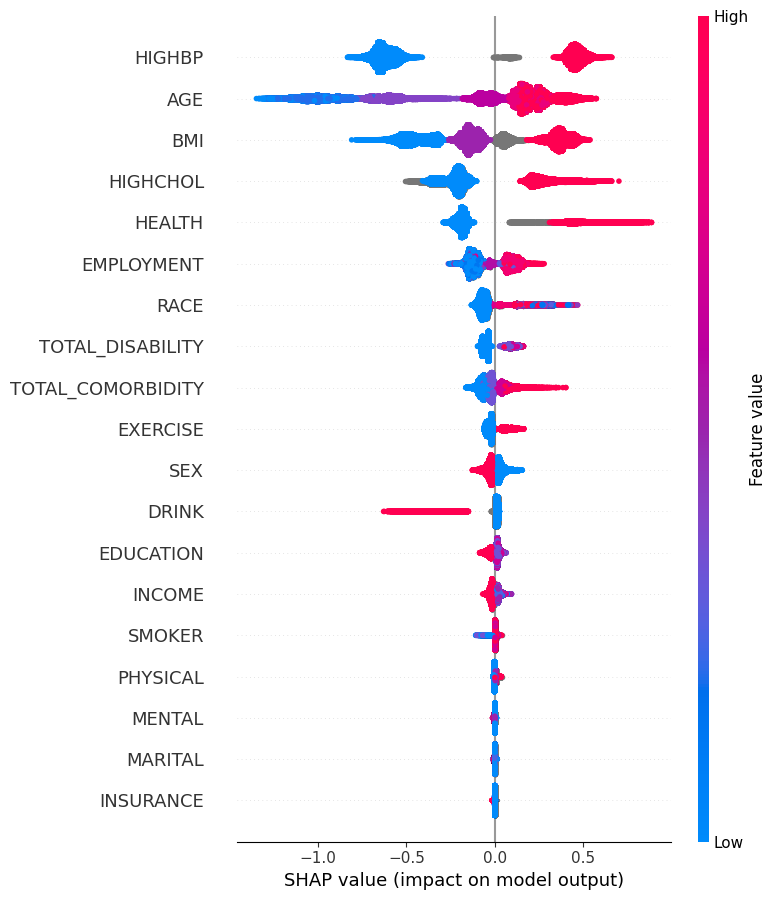

In [31]:
shap.summary_plot(explanation)

In [14]:
shap_val1, base_val1 = dt1.parallel_explain(X, batch_size=100000)

batch 0~100000 done.
batch 100000~200000 done.
batch 200000~300000 done.
batch 300000~400000 done.
batch 400000~500000 done.
batch 500000~600000 done.
batch 600000~700000 done.
batch 700000~800000 done.
batch 800000~900000 done.
batch 900000~1000000 done.
batch 1000000~1100000 done.
batch 1100000~1200000 done.
batch 1200000~1300000 done.
batch 1300000~1400000 done.
batch 1400000~1500000 done.
batch 1500000~1600000 done.
batch 1600000~1700000 done.
batch 1700000~1722563 done.


In [15]:
from_shap1 = shap_val1.sum(axis=1) + base_val1

In [16]:
y_predraw1 = dt1.predict_raw(X)

In [17]:
mask = np.isclose(from_shap1, y_predraw1)

In [18]:
from_shap1

array([ 0.90386637,  0.6301504 ,  1.59257205, ...,  1.51367529,
       -1.07340864, -1.57118968], shape=(1722563,))

In [19]:
y_predraw1

array([ 0.90386633,  0.6301504 ,  1.59257207, ...,  1.51367552,
       -1.07340879, -1.57118993], shape=(1722563,))

In [23]:
y_predraw1[~mask]

array([-0.01335835, -0.00210878,  0.00902291, ...,  0.0029491 ,
        0.00064944,  0.01827974], shape=(8999,))

In [21]:
from_shap1[~mask]

array([-0.01335851, -0.00210867,  0.00902279, ...,  0.00294902,
        0.00064923,  0.01827951], shape=(8999,))

In [25]:
feature_names = df.columns[1:]
feature_names

['SEX',
 'INCOME',
 'HIGHBP',
 'HIGHCHOL',
 'DRINK',
 'INSURANCE',
 'AGE',
 'RACE',
 'MARITAL',
 'EDUCATION',
 'EMPLOYMENT',
 'BMI',
 'HEALTH',
 'PHYSICAL',
 'MENTAL',
 'SMOKER',
 'EXERCISE',
 'TOTAL_COMORBIDITY',
 'TOTAL_DISABILITY']

In [26]:
explanation1 = shap.Explanation(
    values=shap_val1,
    base_values=base_val1,
    data=X,
    feature_names=feature_names,
)

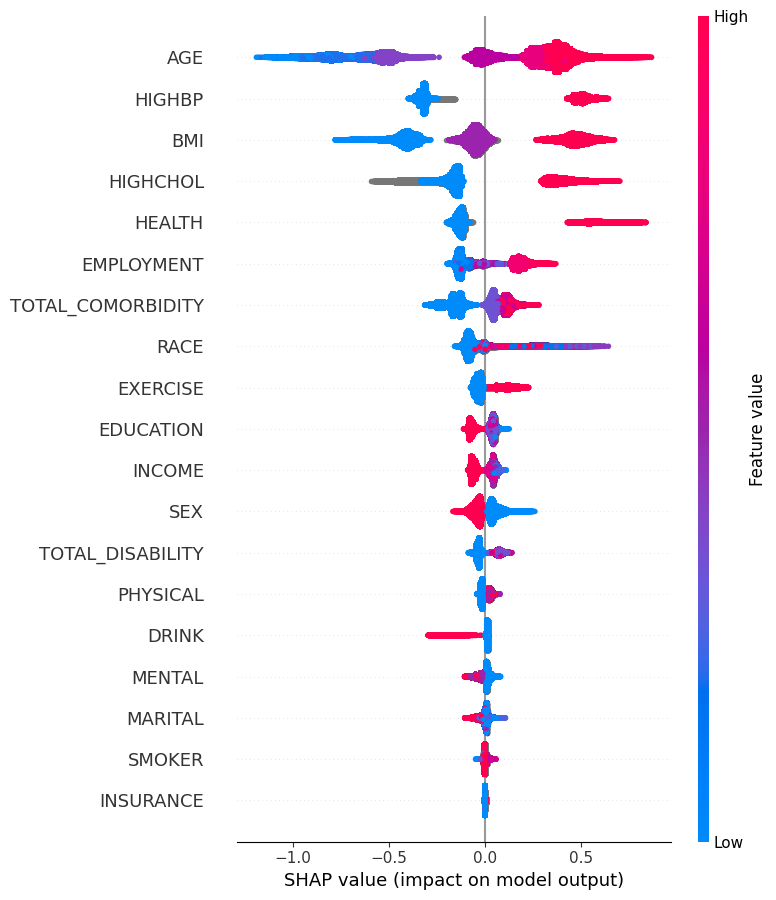

In [27]:
shap.summary_plot(explanation1)

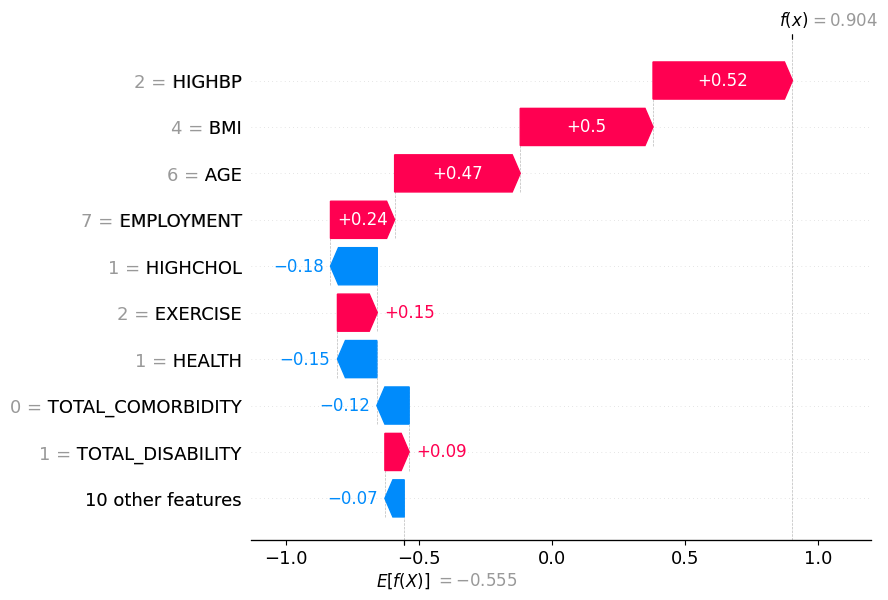

In [28]:
shap.plots.waterfall(explanation1[0])